In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [ ]:
arquivo = files.upload()

Saving imagem_01.png to imagem_01.png
Saving imagem_02.png to imagem_02.png
Saving imagem_04.png to imagem_04.png


In [ ]:
def analisar_imagem(img_path, operacao, params=None):
    # carrega a imagem e converter para tons de cinza
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        print(f"Erro: Imagem {img_path} não encontrada.")
        return
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # aplica a operação escolhida
    img_out = img_gray.copy()
    if operacao == 'equalizacao':
        img_out = cv2.equalizeHist(img_gray)
    elif operacao == 'gamma':
        gamma = params.get('gamma', 1.0)
        invGamma = 1.0 / gamma
        table = np.array([((i / 255.0) ** invGamma) * 255 for i in np.arange(0, 256)]).astype("uint8")
        img_out = cv2.LUT(img_gray, table)
    elif operacao == 'limiarizacao':
        limiar = params.get('limiar', 127)
        _, img_out = cv2.threshold(img_gray, limiar, 255, cv2.THRESH_BINARY)
    else:
        print(f"Operação '{operacao}' não reconhecida.")

    fig, axs = plt.subplots(2, 2, figsize=(12, 8))

    # imagens
    axs[0, 0].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
    axs[0, 0].set_title('Antes (Original)')
    axs[0, 0].axis('off')

    axs[0, 1].imshow(img_out, cmap='gray', vmin=0, vmax=255)
    axs[0, 1].set_title(f'Depois ({operacao.capitalize()})')
    axs[0, 1].axis('off')

    # histogramas
    axs[1, 0].hist(img_gray.ravel(), 256, [0,256], color='black')
    axs[1, 0].set_title('Histograma - Antes')

    axs[1, 1].hist(img_out.ravel(), 256, [0,256], color='black')
    axs[1, 1].set_title('Histograma - Depois')

    plt.tight_layout()
    plt.show()

/tmp/ipykernel_541/1297520049.py:38: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axs[1, 0].hist(img_gray.ravel(), 256, [0,256], color='black')
/tmp/ipykernel_541/1297520049.py:41: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axs[1, 1].hist(img_out.ravel(), 256, [0,256], color='black')


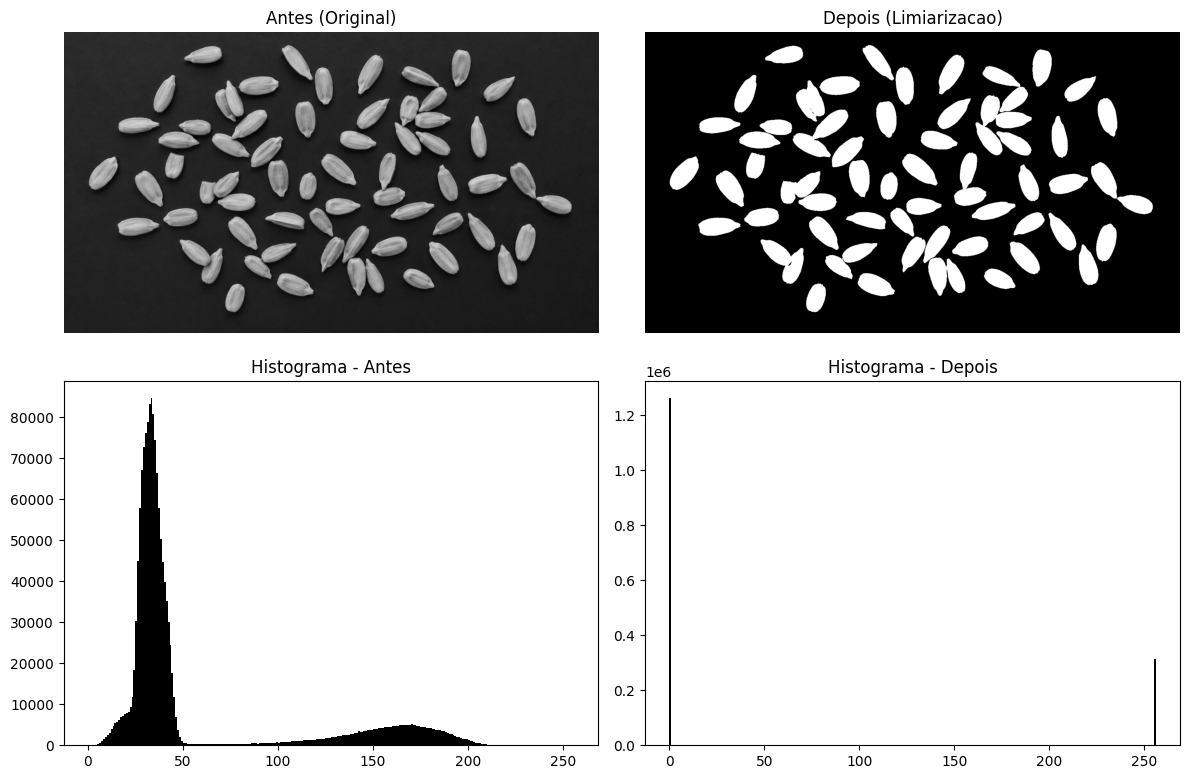

In [ ]:
analisar_imagem('imagem_01.png', 'limiarizacao', {'limiar': 60})

# Imagem 1 — Limiarização
O histograma tinha dois picos bem separados (fundo escuro entre 0 e 50, sementes claras entre 100-200) e uma parte quase vazia no meio. Como já dava pra separar objeto e fundo só pela intensidade, não fazia sentido usar equalização ou expansão de contraste (que servem pra melhorar contraste geral, não separar grupos). Usamos o vale (limiar = 60) como ponto de corte e a segmentação ficou muito boa.

/tmp/ipykernel_541/1703392341.py:36: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axs[1, 0].hist(img_gray.ravel(), 256, [0,256], color='black')
/tmp/ipykernel_541/1703392341.py:39: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axs[1, 1].hist(img_out.ravel(), 256, [0,256], color='black')


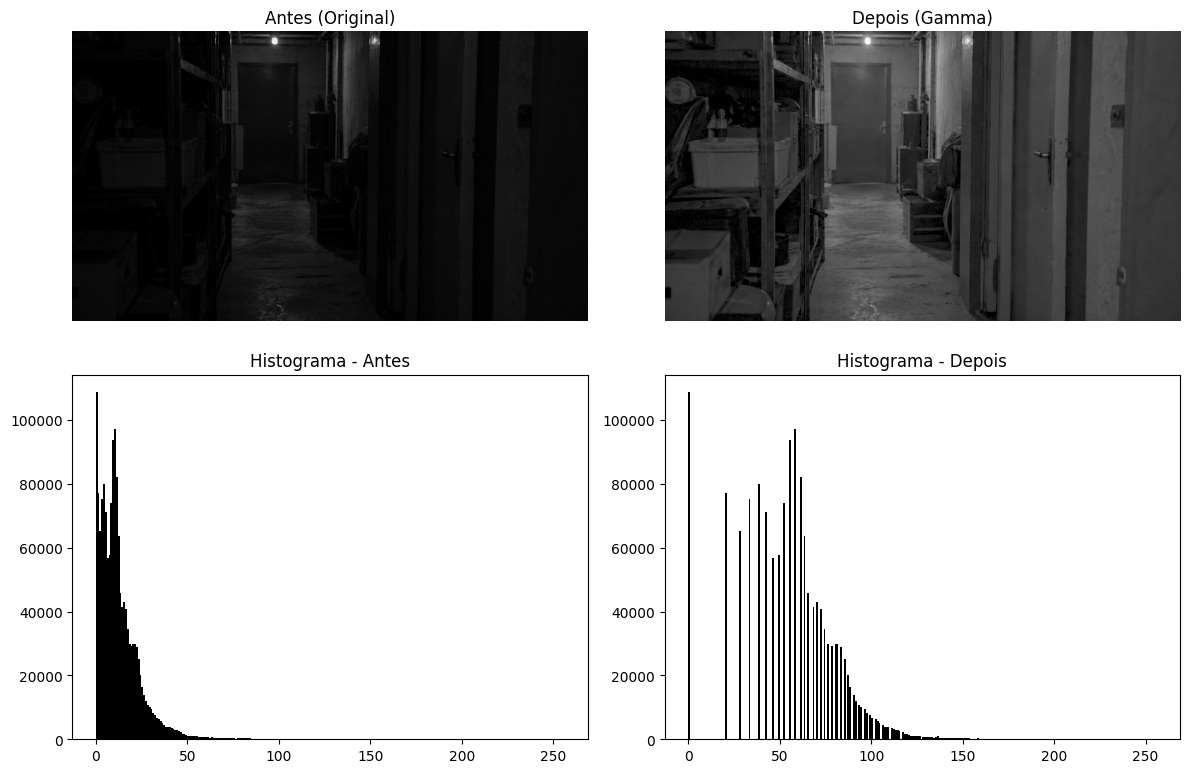

In [ ]:
analisar_imagem('imagem_02.png', 'gamma', {'gamma': 2.2})

# Imagem 2 — Correção Gamma
A imagem estava bem escura, com quase tudo concentrado perto do 0 no histograma. Escolhemos gamma (γ = 2.2) em vez de equalização porque a curva do gamma dá mais controle pra clarear as sombras sem exagerar, a equalização tende a espalhar o histograma de forma mais brusca e podia deixar o resultado com aspecto estranho numa imagem tão escura.

/tmp/ipykernel_541/1297520049.py:38: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axs[1, 0].hist(img_gray.ravel(), 256, [0,256], color='black')
/tmp/ipykernel_541/1297520049.py:41: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axs[1, 1].hist(img_out.ravel(), 256, [0,256], color='black')


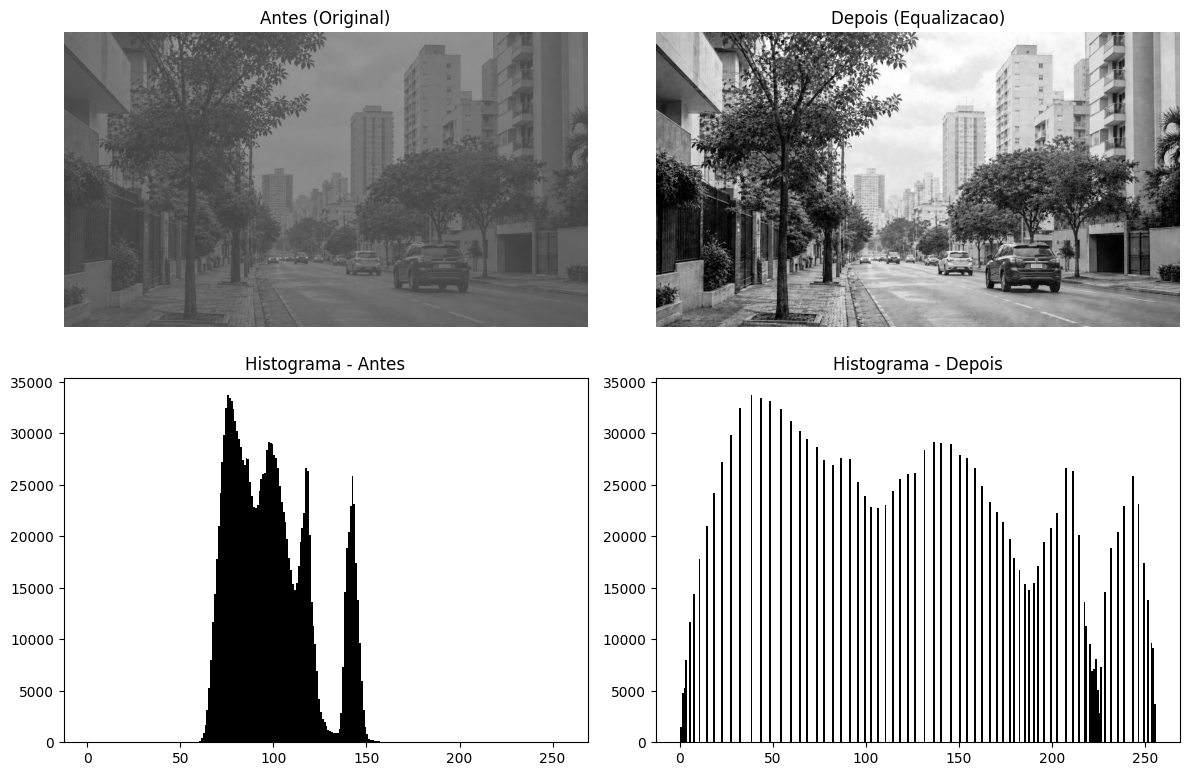

In [ ]:
analisar_imagem('imagem_04.png', 'equalizacao')

# Imagem 4 — Equalização de Histograma
A imagem tinha um aspecto esbranquiçado, e o histograma confirmou isso: todos os valores ficavam espremidos entre 60 e 160, sem chegar perto do preto ou do branco. Optamos por equalização em vez de expansão simples porque ela não só estica os valores, redistribui os pixels pela faixa toda, dando um contraste bem mais forte.

In [ ]:
def quantizar(img, niveis):
    passo = 256 // niveis
    img_quant = (img // passo) * passo
    return img_quant.astype('uint8')

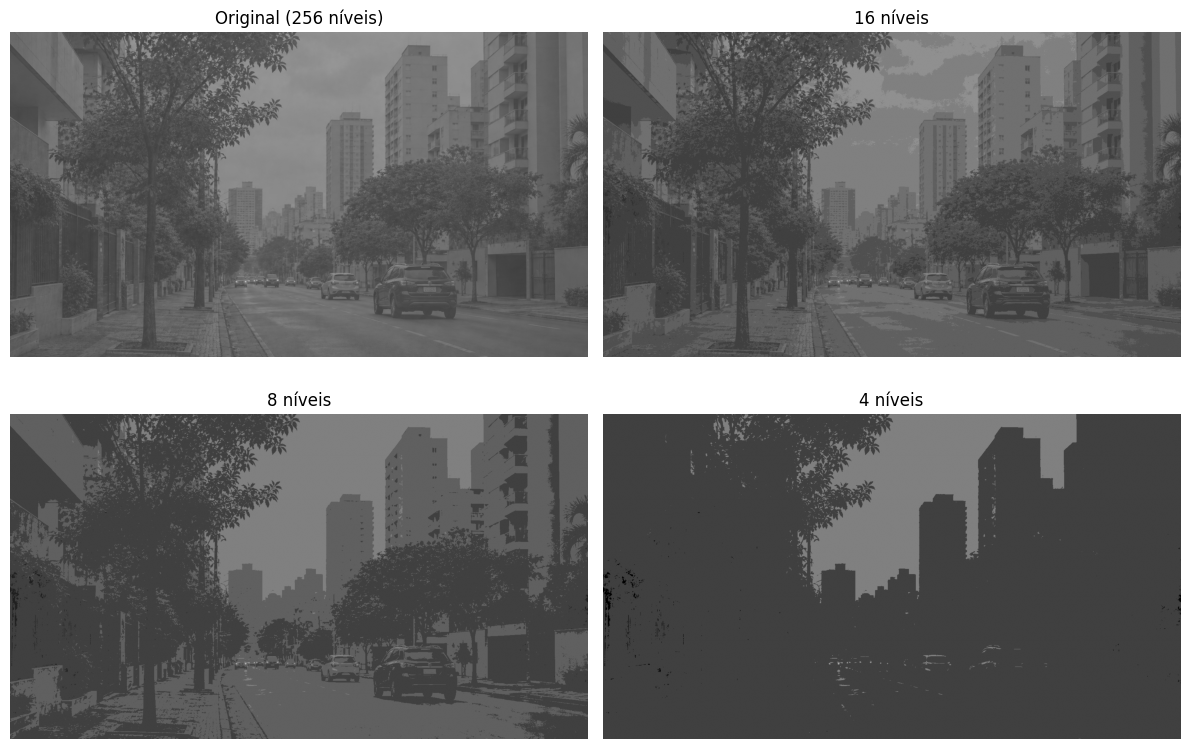

In [ ]:
img1_gray = cv2.cvtColor(cv2.imread('imagem_04.png'), cv2.COLOR_BGR2GRAY)

img_16 = quantizar(img1_gray, 16)
img_8 = quantizar(img1_gray, 8)
img_4 = quantizar(img1_gray, 4)

fig, axs = plt.subplots(2, 2, figsize=(12, 8))

axs[0, 0].imshow(img1_gray, cmap='gray', vmin=0, vmax=255)
axs[0, 0].set_title('Original (256 níveis)')
axs[0, 0].axis('off')

axs[0, 1].imshow(img_16, cmap='gray', vmin=0, vmax=255)
axs[0, 1].set_title('16 níveis')
axs[0, 1].axis('off')

axs[1, 0].imshow(img_8, cmap='gray', vmin=0, vmax=255)
axs[1, 0].set_title('8 níveis')
axs[1, 0].axis('off')

axs[1, 1].imshow(img_4, cmap='gray', vmin=0, vmax=255)
axs[1, 1].set_title('4 níveis')
axs[1, 1].axis('off')

plt.tight_layout()
plt.show()

# Imagem 4 (de novo) - Quantização
Escolhemos essa imagem porque, mesmo com pouco contraste original, ela tem várias áreas de tom parecido (céu, fachadas, calçada), o que deixa bem visível o efeito da quantização. Com 16 níveis a perda é mínima. Com 8 já aparece uma posterização perceptível, principalmente no céu. Com 4 níveis a perda fica bem grave: o céu e várias partes da cena se fundem num único tom, perdendo praticamente toda a separação entre os elementos da imagem.